> **NOTICE**
>
> **Warning:** survivorship bias. The stock universe in this case is a list of companies that survived to today. Companies that failed, were delisted or were acquired are missing, so the equity results are likely optimistic. Read them as an upper bound.
>
> **Purpose:** This case shares the strategy logic so you can re-run it on survivorship-free data, for example point-in-time index membership that includes delisted companies and their full price history. Swap the universe and the price loader, keep the rules, and compare the results. The published numbers are for the survivor universe only and must not be read as a realistic estimate.

# Backtest Autopsy #2: a daily-refit VAR on 19 assets, no forecasting skill, then costs

**Tags:** no forecast skill (not in the taxonomy yet) is the lead finding; cost model is secondary

## TL;DR

* **Idea.** Every day, refit a joint vector autoregression (VAR) on the trailing daily returns of 19 instruments (6 FX pairs, gold, 2 crypto coins, 10 US equities), use its one-day-ahead forecast vector as the signal, and hold equal-notional long/short positions.
* **Result over 125 out-of-sample days** on an illustrative initial equity of 100,000 USD: gross P&L of **-449 USD** (-0.45% of equity), costs of **6,797 USD** (6.8% of equity), net P&L of **-7,246 USD** (net return -7.2%, annualised Sharpe -2.5).
* **Verdict number.** The forecast's directional hit rate was 51.2% and its out-of-sample R-squared against a zero forecast was -0.049: **no forecasting skill**, so gross P&L is about zero. Costs then turn "no edge" into a certain loss; section 9.4 shows how that cost share changes between 5,000 and 250,000 USD of equity.
* **Killing tests.** Label-permutation of the forecast (48% of shuffled forecasts do as well), a cost-multiplier sweep (no cost level is profitable because gross is not positive), and a capital sweep that separates fixed per-order minimums from proportional cost.
* **Note.** The initial equity of 100,000 USD is an illustrative assumption. Results at other capital levels are in section 9.4.

> Outputs below come from a run on the real data. With `AUTOPSY_SYNTHETIC=1` the notebook runs end to end on a synthetic panel with the same schema and will **not** reproduce the failure (a random walk has no skill and no real cost structure).

### Prerequisites

* Python 3.10+, `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib`, and the shared package `autopsy_common` (`pip install -e ../..`).
* Familiarity with: log returns, ordinary least squares, information criteria (AIC/BIC), walk-forward evaluation, and the difference between gross and net P&L.
* Data: your own copies of the raw files described in the data section, in a folder named by `AUTOPSY_DATA_DIR`. No data is shipped with this repository.

## 1. Settings (control panel)

Every governing constant lives in one dictionary, so a reader can see the whole experiment at a glance and so that no magic number hides inside a loop. The values below are the starting point for this case. Change them and re-run the test to see whether the verdict holds; the README lists the implementation notes.

Two environment variables select the mode:

* `AUTOPSY_SYNTHETIC=1` builds a synthetic panel (same schema, no vendor data).
* `AUTOPSY_DATA_DIR` points at the folder holding your raw files.

In [1]:
from __future__ import annotations

import itertools
import json
import os
import subprocess
import sys
import tempfile
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Callable, Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from autopsy_common.data import use_synthetic
from autopsy_common.metrics import block_bootstrap_sharpe, cscv_pbo, sharpe_ratio
from autopsy_common.perf import (drawdown_series, monthly_returns, performance_summary,
                                 rolling_sharpe, yearly_returns)
from autopsy_common.sweep import capital_sweep
from autopsy_common.plots import (plot_bar_contribution, plot_capital_sweep, plot_cost_decomposition, plot_drawdown,
                                  plot_equity, plot_exposure_turnover, plot_monthly_heatmap,
                                  plot_return_distribution, plot_rolling_risk, plot_yearly_bars)
from autopsy_common.schema import check_schema
from autopsy_common.synthetic import synthetic_daily_panel

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

SYNTHETIC = use_synthetic()

# ---- universe: 19 instruments in 4 asset classes (order matters only for reporting) ----
FX_SYMBOLS = ["USDJPY", "EURUSD", "USDCAD", "AUDUSD", "USDCHF", "GBPUSD"]
XAU_SYMBOLS = ["XAUUSD"]
CRYPTO_SYMBOLS = ["LTC", "BCH"]
EQUITY_SYMBOLS = ["JPM", "XOM", "JNJ", "PG", "KO", "WMT", "CVX", "PFE", "HD", "CSCO"]

# interleave the classes so the VAR column order carries no meaning
UNIVERSE: List[str] = (EQUITY_SYMBOLS[:4] + FX_SYMBOLS[:3] + CRYPTO_SYMBOLS[:1] + EQUITY_SYMBOLS[4:7]
                       + XAU_SYMBOLS + FX_SYMBOLS[3:] + CRYPTO_SYMBOLS[1:] + EQUITY_SYMBOLS[7:])
ASSET_CLASS: Dict[str, str] = {
    **{s: "fx" for s in FX_SYMBOLS},
    **{s: "xau" for s in XAU_SYMBOLS},
    **{s: "crypto" for s in CRYPTO_SYMBOLS},
    **{s: "equity" for s in EQUITY_SYMBOLS},
}
assert len(UNIVERSE) == 19 and set(UNIVERSE) == set(ASSET_CLASS)

PARAMS: Dict[str, Any] = {
    # capital / sizing
    "capital": 100_000.0,                 # illustrative initial equity in USD (an assumption; see the capital sweep)
    "crypto_exposure_cap_frac": 0.25,     # crypto gross exposure cap, below the broker's real limit

    # model
    "max_p": 5,                           # VAR lag orders 1..max_p are candidates
    "max_q": 0,                           # 0 = plain VAR; > 0 would use the VARMAX path (see section 4.4)
    "selection_criterion": "aic",         # "aic" or "bic"
    "error_cov_type": "diagonal",         # only used when max_q > 0
    "maxiter": 50,                        # only used when max_q > 0
    "return_method": "log",               # "log" or "simple"

    # rolling training window schedule: the largest tier that fits the available history
    "window_tiers": [500, 750, 1000, 1500, 2000],

    # out-of-sample tail of the joint panel (~6 months of trading days); short in synthetic mode
    "oos_days": 40 if SYNTHETIC else 126,

    # costs: public broker fee formulas, plus two slippage assumptions
    "ib_fx_comm_per_order_usd": 2.00,     # FX: flat commission per order
    "ib_xau_bps": 0.20,                   # spot gold: bps of notional
    "ib_crypto_commission_bps": 18.0,     # crypto: bps of notional ...
    "ib_crypto_min_order_usd": 1.75,      # ... with a per-order minimum
    "crypto_slippage_range_frac": 0.05,   # crypto slippage = this fraction of the day's high-low range
    "ibkr_per_share": 0.0035,             # equities: per-share commission ...
    "ibkr_min_order": 0.35,               # ... with a per-order minimum
    "slippage_bps": 3.0,                  # equities: assumed slippage in bps of notional

    # reporting
    "trading_days_per_year": 252,
    "bootstrap_iters": 2000,
    "sharpe_smell_test_threshold": 3.0,
    "random_seed": 7,
}

DATA_DIR = Path(os.environ["AUTOPSY_DATA_DIR"]) if os.environ.get("AUTOPSY_DATA_DIR") else None
FX_FILE = "merged_forex_data_with_xauusd.csv"        # raw FX + gold 1-minute bid/ask bars
CRYPTO_FILE = "merged_crypto_1min.parquet"           # raw crypto 1-minute bars
EQUITY_CACHE = "equity_daily_close.parquet"          # daily equity closes (built by this notebook if absent)
PANEL_START = "2021-08-01"
RESULTS: Dict[str, Any] = {}
print(f"mode: {'SYNTHETIC' if SYNTHETIC else 'REAL DATA'} | OOS days: {PARAMS['oos_days']}")

mode: REAL DATA | OOS days: 126


## 2. Data

### 2.1 Source recipe

| Block | Vendor / product | Instruments | Frequency | Time zone |
|---|---|---|---|---|
| FX majors and spot gold | Interactive Brokers historical data API, FX and spot-metal contracts, `BID` and `ASK` bar series | 6 FX pairs + 1 spot gold | 1 minute | naive timestamps in a fixed UTC-5 offset (no DST) |
| Crypto | Interactive Brokers historical data API, crypto contracts routed to a crypto venue, `TRADES` bars | 2 coins | 1 minute | naive timestamps, same UTC-5 offset |
| US equities | Public daily closes from the `yfinance` package (unadjusted `Close`) | 10 large-cap tickers | daily | exchange session date |

**How to rebuild.** The FX/gold and crypto files are wide tables: the FX file has one `timestamp` column and, for every symbol, a `<SYM>_final_df__bid_close` and `<SYM>_final_df__ask_close` column; the crypto file has `timestamp` plus `<coin>_open/high/low/close/volume/bar_count/average/symbol/exchange` for every coin. Any provider that gives 1-minute bid/ask for FX and 1-minute trades for the two coins can be pivoted into these two shapes. Equities are fetched by the notebook itself with `yfinance` the first time it runs and cached next to the other files.

### 2.2 What the strategy sees: the daily panel

* **Row definition.** One row is one instrument on one calendar day, after the minute bars are collapsed to a daily close.
* **Key.** `(date, asset)`, unique. **Sort order.** by `date` then `asset`, ascending.
* **Inner join.** A date survives only if all 19 instruments have a valid close that day, so weekends and holidays fall out. The binding start date is the first day both coins exist.
* **Nulls.** None after the inner join. Spread is `0.0` for non-FX/gold instruments (no quoted spread is used for them); high and low equal the close for non-crypto instruments (they are only used by the crypto slippage proxy).

| Column | dtype | Meaning | Units |
|---|---|---|---|
| `date` | datetime | calendar day of the daily bar | day |
| `asset` | string | instrument label | n/a |
| `asset_class` | string | one of `fx`, `xau`, `crypto`, `equity`; drives which cost formula applies | n/a |
| `close` | float64 | last mid (FX/gold) or last trade (crypto) of the day; official close (equity) | quote currency |
| `high` | float64 | day high (crypto) or the close (all others) | quote currency |
| `low` | float64 | day low (crypto) or the close (all others) | quote currency |
| `spread` | float64 | mean bid-ask spread of the day's minute bars (FX/gold); 0 otherwise | quote currency |

Synthetic mode produces a panel with the same columns, a driftless random walk with volatility clustering and no predictability.

In [2]:
PANEL_SCHEMA = {"date": "datetime", "asset": "string", "asset_class": "string",
                "close": "float64", "high": "float64", "low": "float64", "spread": "float64"}
PANEL_KEY = ["date", "asset"]


def build_joint_daily_panel(series_by_symbol: Dict[str, pd.Series]) -> pd.DataFrame:
    """Inner join of every symbol's daily close onto a shared calendar-day index.

    Timestamps are normalised to calendar days first (minute-bar resampling
    leaves a time component), then an inner join keeps only dates where EVERY
    series has a finite observation. Weekends and holidays fall out naturally.
    """
    normalised = {}
    for sym, s in series_by_symbol.items():
        s = s.copy()
        s.index = pd.DatetimeIndex(s.index).normalize()
        s = s[~s.index.duplicated(keep="last")]
        normalised[sym] = s
    panel = pd.DataFrame(normalised, columns=list(series_by_symbol.keys()))
    return panel.dropna(how="any").sort_index()


def load_fx_xau_daily(path: Path, symbols: Sequence[str], start: str = PANEL_START):
    """Daily mid close + daily mean bid/ask spread per FX/gold symbol."""
    cols = ["timestamp"]
    for s in symbols:
        cols += [f"{s}_final_df__bid_close", f"{s}_final_df__ask_close"]
    raw = pd.read_csv(path, usecols=cols, engine="pyarrow")
    raw["timestamp"] = pd.to_datetime(raw["timestamp"])
    raw = raw[raw["timestamp"] >= pd.Timestamp(start)].set_index("timestamp")
    closes, spreads = {}, {}
    for s in symbols:
        bid, ask = raw[f"{s}_final_df__bid_close"], raw[f"{s}_final_df__ask_close"]
        closes[s] = ((bid + ask) / 2.0).resample("1D").last()
        spreads[s] = (ask - bid).clip(lower=0.0).resample("1D").mean()
    return pd.DataFrame(closes).dropna(how="all"), pd.DataFrame(spreads)


def load_crypto_daily(path: Path, symbols: Sequence[str]):
    """Daily close/high/low per coin, from the minute-bar parquet."""
    key = {s: s.lower() for s in symbols}
    cols = ["timestamp"] + [f"{k}_{f}" for k in key.values() for f in ("high", "low", "close")]
    raw = pd.read_parquet(path, columns=cols).set_index("timestamp").sort_index()
    closes, highs, lows = {}, {}, {}
    for s, k in key.items():
        closes[s] = raw[f"{k}_close"].resample("1D").last()
        highs[s] = raw[f"{k}_high"].resample("1D").max()
        lows[s] = raw[f"{k}_low"].resample("1D").min()
    return pd.DataFrame(closes).dropna(how="all"), pd.DataFrame(highs), pd.DataFrame(lows)


def load_equity_daily(data_dir: Path, symbols: Sequence[str], start: str = PANEL_START) -> pd.DataFrame:
    """Daily closes for the equities: cached file if present, else one yfinance download."""
    cache = data_dir / EQUITY_CACHE
    if cache.exists():
        df = pd.read_parquet(cache)
        if set(symbols) <= set(df.columns):
            return df[list(symbols)].copy()
    import yfinance as yf  # only needed on the first real run

    raw = yf.download(list(symbols), start=start, auto_adjust=False, progress=False)["Close"]
    raw.index = pd.DatetimeIndex(raw.index).tz_localize(None)
    raw[list(symbols)].to_parquet(cache)
    return raw[list(symbols)].copy()


def build_real_panel(data_dir: Path) -> pd.DataFrame:
    """Raw files -> long daily panel in PANEL_SCHEMA."""
    fx_close, fx_spread = load_fx_xau_daily(data_dir / FX_FILE, FX_SYMBOLS + XAU_SYMBOLS)
    cr_close, cr_high, cr_low = load_crypto_daily(data_dir / CRYPTO_FILE, CRYPTO_SYMBOLS)
    eq_close = load_equity_daily(data_dir, EQUITY_SYMBOLS)
    series = {}
    for s in FX_SYMBOLS + XAU_SYMBOLS:
        series[s] = fx_close[s]
    for s in CRYPTO_SYMBOLS:
        series[s] = cr_close[s]
    for s in EQUITY_SYMBOLS:
        series[s] = eq_close[s]
    prices = build_joint_daily_panel({s: series[s] for s in UNIVERSE})
    spread = pd.DataFrame(0.0, index=prices.index, columns=UNIVERSE)
    for s in FX_SYMBOLS + XAU_SYMBOLS:
        sp = fx_spread[s].copy()
        sp.index = pd.DatetimeIndex(sp.index).normalize()
        spread[s] = sp.reindex(prices.index).fillna(0.0)
    high, low = prices.copy(), prices.copy()
    for s in CRYPTO_SYMBOLS:
        h, l = cr_high[s].copy(), cr_low[s].copy()
        h.index, l.index = pd.DatetimeIndex(h.index).normalize(), pd.DatetimeIndex(l.index).normalize()
        high[s], low[s] = h.reindex(prices.index), l.reindex(prices.index)
    frames = []
    for s in UNIVERSE:
        frames.append(pd.DataFrame({"date": prices.index, "asset": s, "asset_class": ASSET_CLASS[s],
                                    "close": prices[s].values, "high": high[s].values,
                                    "low": low[s].values, "spread": spread[s].values}))
    return pd.concat(frames, ignore_index=True)


def panel_to_data(panel: pd.DataFrame, method: str) -> Dict[str, pd.DataFrame]:
    """Long panel -> the wide frames the strategy consumes."""
    wide = {c: panel.pivot(index="date", columns="asset", values=c)[UNIVERSE]
            for c in ("close", "high", "low", "spread")}
    prices = wide["close"]
    rets = compute_returns(prices, method=method)
    return {"prices": prices, "returns": rets, "spread": wide["spread"], "high": wide["high"], "low": wide["low"]}


def compute_returns(prices: pd.DataFrame, method: str = "log") -> pd.DataFrame:
    """Per-series daily returns from the aligned price panel."""
    if method == "log":
        rets = np.log(prices / prices.shift(1))
    elif method == "simple":
        rets = prices.pct_change()
    else:
        raise ValueError(f"method must be 'log' or 'simple', got {method!r}")
    return rets.dropna(how="any")


if SYNTHETIC:
    panel = synthetic_daily_panel(UNIVERSE, n_days=900, seed=PARAMS["random_seed"], asset_classes=ASSET_CLASS)
    panel["spread"] = np.where(panel["asset_class"].isin(["fx", "xau"]), panel["spread"], 0.0)
    panel = panel[list(PANEL_SCHEMA)].sort_values(PANEL_KEY).reset_index(drop=True)
else:
    if DATA_DIR is None:
        raise RuntimeError("Set AUTOPSY_SYNTHETIC=1, or AUTOPSY_DATA_DIR to the folder with your raw files.")
    panel = build_real_panel(DATA_DIR).sort_values(PANEL_KEY).reset_index(drop=True)

### 2.3 Schema check

Only pass/fail checks are printed (schema, nulls, key uniqueness and sort order); no counts, dates or values.

In [3]:
print("no nulls in any column:", not bool(panel.isna().any().any()))
print("key unique:", bool(panel.duplicated(PANEL_KEY).sum() == 0), "| sorted by key:", bool(panel.set_index(PANEL_KEY).index.is_monotonic_increasing))
print("schema check passed:", check_schema(panel, PANEL_SCHEMA, PANEL_KEY))

no nulls in any column: True
key unique: True | sorted by key: True
schema check passed: True


## 3. Step 1: from prices to a return panel

The model is fit on **log returns** `r_t = ln(P_t / P_{t-1})`. Log returns are additive over time and roughly symmetric, which is what a linear time-series model assumes. P&L is later accrued on the arithmetic equivalent `exp(r) - 1`, because a position's dollar gain is arithmetic.

What can go wrong here:

* **Calendar mismatch.** FX and crypto trade on weekends; equities do not. The inner join silently discards every day any series is missing, so one illiquid series shortens the history of all 19. The first date both coins existed is the binding constraint.
* **Return synchronicity.** Daily closes are taken at different clock times for different markets (an FX close, a crypto close and an equity close do not share a timestamp). A VAR can mistake that asynchronous timing for lead-lag structure, which is a classic source of apparent predictability that vanishes in execution.

In [4]:
data = panel_to_data(panel, method=str(PARAMS["return_method"]))
returns = data["returns"]
print(f"return panel built (method: {PARAMS['return_method']})")

return panel built (method: log)


## 4. Step 2: the model

### 4.1 What a VAR(p) is

For the vector `y_t` of 19 daily log returns, a VAR(p) assumes

`y_t = c + A_1 y_{t-1} + ... + A_p y_{t-p} + e_t`

Every return is regressed on `p` lags of **all** 19 returns, so each equation has `19p + 1` coefficients and the whole system has `19 (19p + 1)` of them. Estimated by ordinary least squares equation by equation there is a closed form, no optimiser, no convergence risk. At `p = 5` that is 1,824 coefficients fitted from at most 1,000 daily observations of 19 series. The ratio of parameters to observations is the first warning sign.

### 4.2 Choosing p

Each day all candidates `p = 1..5` are fit and the one with the lowest information criterion wins. AIC trades log-likelihood against `2 * n_parameters`; BIC penalises parameters more heavily. Note what is being optimised: statistical fit of the return panel, **not** trading profit. A model can win on AIC and still have no profitable signal.

### 4.3 The signal

The one-step-ahead forecast `E[y_{t+1} | information up to t]` is a 19-vector. Its **sign** per asset is the position direction for the next day. The forecast is made from the close of day `t`; positions are held over `t+1`. The training window ends at `t` and contains only data known at `t`, so there is no look-ahead in the signal.

### 4.4 Why VAR and not VARMA

The fuller design is a VARMA(p, q) with a moving-average term. VARMA has no closed-form fit: it needs iterative state-space maximum likelihood, and the cost grows steeply with the number of series. Section 4.6 measures this directly instead of asserting it. The strategy therefore runs with `max_q = 0` (plain VAR); the VARMAX code path is kept so that `max_q > 0` still works on a small universe.

In [5]:
def pq_grid(max_p: int = 5, max_q: int = 5) -> List[Tuple[int, int]]:
    """All (p, q) in [0..max_p] x [0..max_q] EXCLUDING (0, 0).

    (0, 0) is excluded because a model with neither AR nor MA terms is a
    constant-mean model and carries no dynamics to forecast from.
    """
    return [(p, q) for p, q in itertools.product(range(max_p + 1), range(max_q + 1))
            if not (p == 0 and q == 0)]


def select_window_tier(available_history: int, tiers: Sequence[int]) -> Optional[int]:
    """Largest tier that fits in ``available_history``, or None if none does.

    General in the tier ladder: nothing about which tier "should" get used is
    hardcoded. The natural cap is simply max(tiers).
    """
    fitting = [t for t in sorted(tiers) if t <= available_history]
    return fitting[-1] if fitting else None


@dataclass
class VarmaFitResult:
    fit: Any
    order: Tuple[int, int]
    criterion_value: float
    n_attempted: int
    n_converged: int
    used_fallback: bool
    refit_date: pd.Timestamp

    @property
    def convergence_rate(self) -> float:
        return self.n_converged / self.n_attempted if self.n_attempted else 0.0


class _VarmaxFitWrapper:
    """Thin wrapper so the walk-forward only ever needs .aic/.bic/.forecast_next."""

    def __init__(self, results, columns: Sequence[str]):
        self._results = results
        self._columns = list(columns)
        self.aic = float(results.aic)
        self.bic = float(results.bic)

    def forecast_next(self, columns: Sequence[str]) -> Dict[str, float]:
        values = np.asarray(self._results.forecast(steps=1)).reshape(-1)
        return {c: float(values[i]) for i, c in enumerate(self._columns) if c in set(columns)}


class _VarFitWrapper:
    """Same .aic/.bic/.forecast_next interface, for a closed-form OLS VAR(p) fit.
    Unlike VARMAX, VAR.forecast() is stateless and needs the trailing p
    observations passed back in explicitly."""

    def __init__(self, results, last_obs: np.ndarray, columns: Sequence[str]):
        self._results = results
        self._last_obs = last_obs  # last k_ar rows of the training data
        self._columns = list(columns)
        self.aic = float(results.aic)
        self.bic = float(results.bic)

    def forecast_next(self, columns: Sequence[str]) -> Dict[str, float]:
        values = np.asarray(self._results.forecast(self._last_obs, steps=1)).reshape(-1)
        return {c: float(values[i]) for i, c in enumerate(self._columns) if c in set(columns)}


def _fit_varmax(train: pd.DataFrame, p: int, q: int, params: Dict[str, Any]):
    """Real fit for one (p, q) candidate. Raises on any estimation failure.

    q == 0 uses statsmodels' dedicated VAR class: a closed-form OLS fit, no
    iterative optimiser. q > 0 falls back to VARMAX's iterative state-space MLE.
    """
    if q == 0:
        if p == 0:
            raise ValueError("(p, q) = (0, 0) is not a meaningful model")
        from statsmodels.tsa.api import VAR  # local import: heavy

        with warnings.catch_warnings():
            warnings.simplefilter("error", category=RuntimeWarning)
            warnings.simplefilter("ignore")
            res = VAR(train.values).fit(p)
        if not np.isfinite(res.aic) or not np.isfinite(res.bic):
            raise RuntimeError("non-finite information criterion")
        return _VarFitWrapper(res, train.values[-res.k_ar:], train.columns)

    from statsmodels.tsa.statespace.varmax import VARMAX  # local import: heavy

    with warnings.catch_warnings():
        warnings.simplefilter("error", category=RuntimeWarning)
        warnings.simplefilter("ignore")
        model = VARMAX(train.values, order=(p, q), trend="c",
                       error_cov_type=str(params["error_cov_type"]),
                       enforce_stationarity=True, enforce_invertibility=True)
        res = model.fit(disp=False, maxiter=int(params["maxiter"]))
    if not np.isfinite(res.aic) or not np.isfinite(res.bic):
        raise RuntimeError("non-finite information criterion")
    return _VarmaxFitWrapper(res, train.columns)


def fit_best_varma(train: pd.DataFrame, refit_date: pd.Timestamp, params: Dict[str, Any],
                   previous: Optional[VarmaFitResult] = None,
                   fit_fn: Callable[..., Any] = _fit_varmax,
                   log_fn: Callable[[dict], None] = lambda rec: None,
                   grid: Optional[Iterable[Tuple[int, int]]] = None) -> Optional[VarmaFitResult]:
    """Fit every (p, q) candidate, log every failure, return the best by AIC/BIC.

    Failures are a DIAGNOSTIC, never hidden: each failed candidate is logged
    with its order, refit date and reason. If nothing converges, the previous
    day's fitted model is carried forward (also logged). If nothing converges
    and there is no previous model, None is returned.
    """
    criterion = str(params.get("selection_criterion", "aic")).lower()
    if criterion not in ("aic", "bic"):
        raise ValueError(f"selection_criterion must be 'aic' or 'bic', got {criterion!r}")
    candidates = list(grid) if grid is not None else pq_grid(int(params["max_p"]), int(params["max_q"]))

    best_fit, best_order, best_value = None, None, np.inf
    n_converged = 0
    for p, q in candidates:
        try:
            fit = fit_fn(train, p, q, params)
            value = float(getattr(fit, criterion))
            if not np.isfinite(value):
                raise RuntimeError(f"non-finite {criterion}")
        except Exception as exc:  # noqa: BLE001 - any estimation failure is a diagnostic
            log_fn({"refit_date": refit_date, "p": p, "q": q, "event": "candidate_failed",
                    "reason": f"{type(exc).__name__}: {exc}"})
            continue
        n_converged += 1
        if value < best_value:
            best_fit, best_order, best_value = fit, (p, q), value

    n_attempted = len(candidates)
    if best_fit is not None:
        return VarmaFitResult(fit=best_fit, order=best_order, criterion_value=best_value,
                              n_attempted=n_attempted, n_converged=n_converged,
                              used_fallback=False, refit_date=refit_date)
    if previous is not None:
        log_fn({"refit_date": refit_date, "p": previous.order[0], "q": previous.order[1],
                "event": "fallback_to_previous",
                "reason": f"no candidate converged out of {n_attempted}; "
                          f"carrying forward order {previous.order} from {previous.refit_date}"})
        return VarmaFitResult(fit=previous.fit, order=previous.order,
                              criterion_value=previous.criterion_value,
                              n_attempted=n_attempted, n_converged=0,
                              used_fallback=True, refit_date=refit_date)
    log_fn({"refit_date": refit_date, "p": -1, "q": -1, "event": "no_model",
            "reason": f"no candidate converged out of {n_attempted} and no previous model exists"})
    return None

### 4.5 Quick sanity check of the model on one window

One fit on the last available window, with timing. No forecast values are printed, only the selected order and how long the whole candidate grid takes.

In [6]:
_t0 = time.time()
_tier = select_window_tier(len(returns), PARAMS["window_tiers"])
_res = fit_best_varma(returns.iloc[-_tier:], returns.index[-1], PARAMS)
print(f"window tier={_tier} | selected (p, q)={_res.order} | candidates converged="
      f"{_res.n_converged}/{_res.n_attempted} | grid fit time={time.time() - _t0:.1f}s")
print(f"parameters in the selected model: {19 * (19 * _res.order[0] + 1)} "
      f"| observations in window: {_tier * 19}")

window tier=1000 | selected (p, q)=(1, 0) | candidates converged=5/5 | grid fit time=0.2s
parameters in the selected model: 380 | observations in window: 19000


### 4.6 Measured: why VARMA was abandoned

This cell fits one VARMAX(1, 1) with diagonal error covariance on the first `k` series of the panel, in a **separate process with a hard wall-clock timeout** (a stuck optimiser cannot be cancelled from inside the same process). It records whether the optimiser reported convergence and how long it took. The timeout is deliberately short; the point is the trend in `k`, not a precise number.

k= 2  status=not converged  seconds=0.4


k= 4  status=converged      seconds=1.1


k= 6  status=converged      seconds=3.6


k= 8  status=converged      seconds=7.4


k=10  status=converged      seconds=17.1


k=19  status=timeout        seconds=60.1


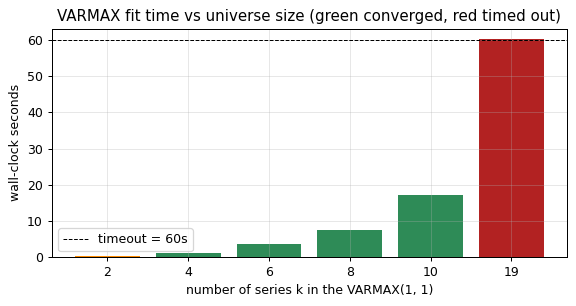

In [7]:
_VARMAX_PROBE = """
import sys, time, warnings
import numpy as np
from statsmodels.tsa.statespace.varmax import VARMAX
x = np.load(sys.argv[1]); maxiter = int(sys.argv[2])
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    res = VARMAX(x, order=(1, 1), trend="c", error_cov_type="diagonal",
                 enforce_stationarity=True, enforce_invertibility=True).fit(disp=False, maxiter=maxiter)
print(int(bool(res.mle_retvals.get("converged", False))), round(time.time() - t0, 1))
"""


def probe_varmax(x: np.ndarray, timeout_s: float, maxiter: int = 50) -> Dict[str, Any]:
    env = dict(os.environ, OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1")
    with tempfile.TemporaryDirectory() as tmp:
        f = Path(tmp) / "x.npy"
        np.save(f, x)
        t0 = time.time()
        try:
            out = subprocess.run([sys.executable, "-c", _VARMAX_PROBE, str(f), str(maxiter)],
                                 capture_output=True, text=True, timeout=timeout_s, env=env)
            if out.returncode != 0:
                return {"status": "error", "seconds": time.time() - t0}
            flag, secs = out.stdout.split()
            return {"status": "converged" if flag == "1" else "not converged", "seconds": float(secs)}
        except subprocess.TimeoutExpired:
            return {"status": "timeout", "seconds": time.time() - t0}


_ks = [2, 4, 6] if SYNTHETIC else [2, 4, 6, 8, 10, 19]
_timeout = 30.0 if SYNTHETIC else 60.0
_train = returns.iloc[-500:]
probe_rows = []
for k in _ks:
    r = probe_varmax(_train.iloc[:, :k].to_numpy(), _timeout)
    probe_rows.append({"k_series": k, **r})
    print(f"k={k:>2}  status={r['status']:<14} seconds={r['seconds']:.1f}")
probe = pd.DataFrame(probe_rows)
RESULTS["varmax_probe"] = probe.to_dict("records")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
colors = probe["status"].map({"converged": "seagreen", "not converged": "darkorange",
                              "timeout": "firebrick", "error": "grey"})
ax.bar(probe["k_series"].astype(str), probe["seconds"], color=colors)
ax.axhline(_timeout, color="k", ls="--", lw=0.8, label=f"timeout = {_timeout:.0f}s")
ax.set_xlabel("number of series k in the VARMAX(1, 1)")
ax.set_ylabel("wall-clock seconds")
ax.set_title("VARMAX fit time vs universe size (green converged, red timed out)")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Step 3: position sizing and costs

### 5.1 Sizing (a documented placeholder, not a validated choice)

The signal is the sign of the VAR forecast; it defines no sizing rule. What runs here is a simple default, and it has not been compared with alternatives:

* **Equal notional per slot:** `capital / 19` per asset that has a live signal that day.
* **Freed capital is not redistributed.** If only 4 of 19 forecasts are non-zero, only about 4/19 of capital is deployed. Exposure never exceeds capital.
* **Direction = sign of the forecast**, except the two coins, which are long-only: a negative crypto forecast means flat, not short (retail crypto cannot be shorted at this broker).
* **Crypto cap** applied during sizing: crypto gross exposure is scaled down proportionally to a fraction of capital (a risk limit inside the sizing function, not a post-hoc clip).

What can go wrong: with 19 slots each slot is capital / 19 (about 5,263 USD at the 100,000 USD headline, 263 USD at 5,000 USD). Fixed per-order minimums are a large share of a small ticket and a small share of a large one; section 9.4 sweeps the capital to separate that part of cost from the proportional part.

### 5.2 Costs

Costs are charged per order on the *traded delta* of target notional, with the formula keyed to the asset's declared class (an unknown class raises instead of silently costing zero). The commission formulas are the public broker fee schedules for each product; the slippage terms are assumptions.

| Class | Commission | Slippage / spread |
|---|---|---|
| FX | flat 2.00 USD per order | notional x (mean daily spread / price) |
| Gold | 0.20 bps of notional | none |
| Crypto | max(18 bps of notional, 1.75 USD) | notional x (day range / price) x 0.05 |
| Equity | max(0.35 USD, 0.0035 USD x shares) | 3 bps of notional |

Each function returns the two components separately so that section 8 can decompose cost into commission and spread/slippage.

In [8]:
def fx_order_cost_parts(notional_usd: float, spread: float, price: float, params: Dict[str, Any]) -> Tuple[float, float]:
    """One FX order, one side: (flat commission, spread cost)."""
    notional_usd = abs(float(notional_usd))
    if notional_usd <= 0.0:
        return 0.0, 0.0
    spread_cost = notional_usd * (float(spread) / float(price)) if price > 0 else 0.0
    return float(params["ib_fx_comm_per_order_usd"]), spread_cost


def xau_order_cost_parts(notional_usd: float, params: Dict[str, Any]) -> Tuple[float, float]:
    """One gold order, one side: bps of notional, no separate spread term."""
    return abs(float(notional_usd)) * float(params["ib_xau_bps"]) / 1e4, 0.0


def crypto_order_cost_parts(notional_usd: float, day_high: float, day_low: float, price: float,
                            params: Dict[str, Any]) -> Tuple[float, float]:
    """One crypto order, one side: (max(bps commission, minimum), day-range slippage proxy)."""
    notional_usd = abs(float(notional_usd))
    if notional_usd <= 0.0:
        return 0.0, 0.0
    comm = max(notional_usd * float(params["ib_crypto_commission_bps"]) / 1e4,
               float(params["ib_crypto_min_order_usd"]))
    day_range_frac = (float(day_high) - float(day_low)) / float(price) if price > 0 else 0.0
    return comm, notional_usd * day_range_frac * float(params["crypto_slippage_range_frac"])


def equity_order_cost_parts(shares: float, price: float, params: Dict[str, Any]) -> Tuple[float, float]:
    """One equity order, one side: (max(minimum, per-share), slippage in bps of notional)."""
    shares = abs(float(shares))
    if shares <= 0.0 or not np.isfinite(price) or price <= 0:
        return 0.0, 0.0
    notional = shares * float(price)
    comm = max(float(params["ibkr_min_order"]), float(params["ibkr_per_share"]) * shares)
    return comm, notional * float(params["slippage_bps"]) / 1e4


def order_cost_fixed_part(symbol: str, notional_usd: float, shares: float, params: Dict[str, Any]) -> float:
    """[instrumentation] Part of one order's cost that is a per-order fixed
    amount rather than proportional to notional: the flat FX commission, and
    the crypto/equity minimum ticket when it is the binding term."""
    klass = ASSET_CLASS[symbol]
    n = abs(float(notional_usd))
    if n <= 0.0:
        return 0.0
    if klass == "fx":
        return float(params["ib_fx_comm_per_order_usd"])
    if klass == "crypto":
        bps_comm = n * float(params["ib_crypto_commission_bps"]) / 1e4
        return float(params["ib_crypto_min_order_usd"]) if bps_comm < float(params["ib_crypto_min_order_usd"]) else 0.0
    if klass == "equity":
        per_share = float(params["ibkr_per_share"]) * abs(float(shares))
        return float(params["ibkr_min_order"]) if per_share < float(params["ibkr_min_order"]) else 0.0
    return 0.0


def order_cost_parts(symbol: str, notional_usd: float, price: float, spread: float, shares: float,
                     day_high: float, day_low: float, params: Dict[str, Any]) -> Tuple[float, float]:
    """Dispatch one order's cost on the symbol's DECLARED ASSET CLASS.

    Keyed off ASSET_CLASS, never off the symbol string itself, so the universe
    stays extensible and an unknown symbol fails loudly instead of silently
    getting a wrong (or zero) cost.
    """
    klass = ASSET_CLASS[symbol]
    if klass == "fx":
        return fx_order_cost_parts(notional_usd, spread, price, params)
    if klass == "xau":
        return xau_order_cost_parts(notional_usd, params)
    if klass == "crypto":
        return crypto_order_cost_parts(notional_usd, day_high, day_low, price, params)
    if klass == "equity":
        return equity_order_cost_parts(shares, price, params)
    raise KeyError(f"no cost model for asset class {klass!r}")


def target_notionals(forecasts: Dict[str, float], params: Dict[str, Any],
                     universe: Sequence[str] = UNIVERSE) -> Dict[str, float]:
    """Signed target notional per asset for the next day.

    DOCUMENTED PLACEHOLDER: equal notional per active slot, freed capital left
    uninvested, crypto long-only, crypto gross capped at
    ``crypto_exposure_cap_frac`` of capital inside this function.
    """
    capital = float(params["capital"])
    per_slot = capital / len(universe)
    crypto_cap_usd = capital * float(params["crypto_exposure_cap_frac"])

    out: Dict[str, float] = {}
    for sym in universe:
        f = forecasts.get(sym, np.nan)
        if f is None or not np.isfinite(f) or f == 0.0:
            out[sym] = 0.0
            continue
        if sym in CRYPTO_SYMBOLS and f < 0.0:
            out[sym] = 0.0           # retail crypto is long-only
            continue
        out[sym] = per_slot if f > 0 else -per_slot

    crypto_gross = sum(abs(out[s]) for s in CRYPTO_SYMBOLS if s in out)
    if crypto_gross > crypto_cap_usd and crypto_gross > 0:
        scale = crypto_cap_usd / crypto_gross
        for s in CRYPTO_SYMBOLS:
            if s in out:
                out[s] *= scale
    return out


def realized_trade_return(entry_price: float, exit_price: float, direction: str) -> float:
    """Signed realised return of one closed position. One shared helper for
    BOTH close paths (mid-walk direction flip and end-of-run close)."""
    if direction == "long":
        sign = 1.0
    elif direction == "short":
        sign = -1.0
    else:
        raise ValueError(f"direction must be 'long' or 'short', got {direction!r}")
    return (float(exit_price) / float(entry_price) - 1.0) * sign

## 6. Step 4: the walk-forward loop

For each out-of-sample day `t` (the last `oos_days` rows of the panel):

1. **Choose the window.** Take the largest tier that fits the history available at `t`.
2. **Refit.** Fit every candidate order on the trailing window ending at `t` and keep the best by AIC.
3. **Forecast** the next-day return vector and turn it into target notionals; scale targets by current equity so the book compounds.
4. **Pay costs** on the traded delta against the previous day's positions.
5. **Book P&L** with the realised return of day `t+1` on the target positions.

Rows marked `[instrumentation]` are additions to the loop that only *record* more detail (per-asset P&L and cost, the forecast vector, the realised vector, traded notional); they do not alter any decision. There is no parallel process pool here: with `max_q = 0` the fit is a closed-form OLS, so the candidates are fit one after another and the numbers are identical.

**What can go wrong in a loop like this.** Using `returns.iloc[i + 1 - tier : i + 1]` includes row `i` and nothing after it; the forecast is applied to row `i + 1`. Any off-by-one here would create look-ahead leakage and an unrealistically good backtest.

In [9]:
def run_walk_forward(data: Dict[str, pd.DataFrame], params: Dict[str, Any],
                     universe: Optional[Sequence[str]] = None,
                     oos_days: Optional[int] = None,
                     diagnostics: Optional[List[dict]] = None,
                     progress_every: int = 20) -> Dict[str, Any]:
    """Day-by-day refit walk-forward over the OOS tail of the joint panel.

    At day t the model is fit on the trailing window ending at t (information
    available at t's close), its one-step forecast sizes positions held over
    t+1, and t+1's realised returns and rebalance costs are booked.
    """
    universe = list(universe) if universe is not None else list(UNIVERSE)
    oos_days = int(oos_days if oos_days is not None else params["oos_days"])
    diagnostics = diagnostics if diagnostics is not None else []

    returns = data["returns"][universe]
    prices = data["prices"].loc[returns.index]
    spread = data["spread"].loc[returns.index]
    high = data["high"].loc[returns.index]
    low = data["low"].loc[returns.index]

    n = len(returns)
    oos_start_i = max(1, n - oos_days)
    tiers = list(params["window_tiers"])

    equity = float(params["capital"])
    prev_notional = {s: 0.0 for s in universe}
    open_trades: Dict[str, dict] = {}
    rows, trades, orders_selected, conv_rates = [], [], [], []
    per_asset: List[dict] = []          # [instrumentation]
    forecast_rows, realised_rows = [], []  # [instrumentation]
    previous: Optional[VarmaFitResult] = None
    t0 = time.time()

    for i in range(oos_start_i, n - 1):
        date, next_date = returns.index[i], returns.index[i + 1]
        tier = select_window_tier(i + 1, tiers)
        if tier is None:
            continue
        train = returns.iloc[i + 1 - tier: i + 1]

        res = fit_best_varma(train, date, params, previous=previous, log_fn=diagnostics.append)
        if res is None:
            continue
        previous = res
        conv_rates.append(res.convergence_rate)
        orders_selected.append(res.order)

        forecasts = res.fit.forecast_next(universe)
        target = target_notionals(forecasts, params=params, universe=universe)
        scale = equity / float(params["capital"])
        target = {s: v * scale for s, v in target.items()}

        # Rebalance cost on the traded delta, per asset class.
        cost_by_asset, comm_total, slip_total, traded, fixed_total = {}, 0.0, 0.0, 0.0, 0.0
        for s in universe:
            delta = target[s] - prev_notional[s]
            if abs(delta) < 1e-9:
                cost_by_asset[s] = 0.0
                continue
            px = float(prices.at[date, s])
            comm, slip = order_cost_parts(s, abs(delta), px, float(spread.at[date, s]),
                                          abs(delta) / px if px > 0 else 0.0,
                                          float(high.at[date, s]), float(low.at[date, s]), params)
            cost_by_asset[s] = comm + slip
            fixed_total += order_cost_fixed_part(s, abs(delta), abs(delta) / px if px > 0 else 0.0, params)  # [instrumentation]
            comm_total += comm
            slip_total += slip
            traded += abs(delta)
        cost = comm_total + slip_total

        # Realised PnL over the next day on the arithmetic return.
        pnl, pnl_by_asset = 0.0, {}
        for s in universe:
            r_next = float(returns.at[next_date, s])
            if str(params["return_method"]) == "log":
                r_next = float(np.expm1(r_next))
            pnl_by_asset[s] = target[s] * r_next
            pnl += pnl_by_asset[s]

        prev_equity = equity
        equity = equity + pnl - cost
        gross_notional = sum(abs(v) for v in target.values())
        rows.append({"date": next_date, "equity": equity,
                     "ret": (equity / prev_equity - 1.0) if prev_equity else 0.0,
                     "pnl": pnl, "cost": cost, "p": res.order[0], "q": res.order[1],
                     "window_tier": tier, "convergence_rate": res.convergence_rate,
                     "used_fallback": res.used_fallback, "gross_notional": gross_notional,
                     "commission": comm_total, "slippage": slip_total,   # [instrumentation]
                     "traded_notional": traded, "prev_equity": prev_equity,  # [instrumentation]
                     "fixed_cost": fixed_total})  # [instrumentation]
        per_asset.append({"date": next_date, **{f"pnl_{s}": v for s, v in pnl_by_asset.items()},
                          **{f"cost_{s}": v for s, v in cost_by_asset.items()}})
        forecast_rows.append({"date": next_date, **{s: float(forecasts.get(s, np.nan)) for s in universe}})
        realised_rows.append({"date": next_date, **{s: float(returns.at[next_date, s]) for s in universe}})

        # Trade-level log: a position is a trade from the day it opens (or flips) to the day it closes or flips.
        for s in universe:
            old, new = prev_notional[s], target[s]
            old_dir, new_dir = np.sign(old), np.sign(new)
            if old_dir != new_dir:
                if s in open_trades:
                    tr = open_trades.pop(s)
                    exit_px = float(prices.at[date, s])
                    tr.update({"exit_date": date, "exit_price": exit_px,
                               "holding_days": int((date - tr["entry_date"]).days),
                               "realized_return": realized_trade_return(tr["entry_price"], exit_px, tr["direction"])})
                    trades.append(tr)
                if new_dir != 0:
                    open_trades[s] = {"asset": s, "direction": "long" if new_dir > 0 else "short",
                                      "entry_date": date, "entry_price": float(prices.at[date, s]),
                                      "notional": abs(new), "p": res.order[0], "q": res.order[1],
                                      "window_tier": tier}
            prev_notional[s] = new

        if progress_every and len(rows) % progress_every == 0:
            print(f"  day {len(rows)}/{n - 1 - oos_start_i} done, {time.time() - t0:.0f}s elapsed", flush=True)

    for s, tr in open_trades.items():  # close whatever is still open at the end of the run
        last_date = returns.index[-1]
        exit_px = float(prices.at[last_date, s])
        tr.update({"exit_date": last_date, "exit_price": exit_px,
                   "holding_days": int((last_date - tr["entry_date"]).days),
                   "realized_return": realized_trade_return(tr["entry_price"], exit_px, tr["direction"])})
        trades.append(tr)

    curve = pd.DataFrame(rows).set_index("date")
    return {
        "equity_curve": curve,
        "trade_log": pd.DataFrame(trades),
        "orders": orders_selected,
        "diagnostics": diagnostics,
        "per_asset": pd.DataFrame(per_asset).set_index("date"),
        "forecasts": pd.DataFrame(forecast_rows).set_index("date"),
        "realised": pd.DataFrame(realised_rows).set_index("date"),
        "mean_convergence_rate": float(np.mean(conv_rates)) if conv_rates else 0.0,
        "wall_clock_s": time.time() - t0,
        "n_oos_days": len(rows),
    }

### 6.1 Run it

The real run refits 5 candidate models on a 1,000-row by 19-column window every day; expect a few minutes. Progress is printed every 20 days.

In [10]:
diagnostics: List[dict] = []
result = run_walk_forward(data, PARAMS, diagnostics=diagnostics)
curve = result["equity_curve"]
print(f"OOS days: {result['n_oos_days']} | wall-clock: {result['wall_clock_s']:.0f}s | "
      f"mean convergence rate: {result['mean_convergence_rate']:.2f} | "
      f"failed candidates logged: {sum(1 for d in diagnostics if d['event'] == 'candidate_failed')}")
RESULTS["n_oos_days"] = int(result["n_oos_days"])
RESULTS["wall_clock_s"] = float(result["wall_clock_s"])

  day 20/125 done, 1s elapsed


  day 40/125 done, 1s elapsed


  day 60/125 done, 3s elapsed


  day 80/125 done, 4s elapsed


  day 100/125 done, 4s elapsed


  day 120/125 done, 5s elapsed


OOS days: 125 | wall-clock: 5s | mean convergence rate: 1.00 | failed candidates logged: 0


## 7. Results and metrics

Net returns are the daily returns of the equity curve after costs. Gross returns add the day's cost back (`pnl / previous equity`). **Benchmark.** The strategy defines none, so none is added here: the natural baseline for a long/short overlay is cash (zero return), and no market series is plotted or tabulated. **Exposure** is gross notional divided by equity; **turnover** is traded notional divided by equity.

In [11]:
ppy = int(PARAMS["trading_days_per_year"])
net = curve["ret"]
gross = curve["pnl"] / curve["prev_equity"]
exposure = curve["gross_notional"] / curve["prev_equity"]
turnover = curve["traded_notional"] / curve["prev_equity"]

summary = performance_summary(net, periods_per_year=ppy, gross_returns=gross,
                              turnover=turnover, exposure=exposure)


def order_selection_stability(orders: Sequence[Tuple[int, int]]) -> Dict[str, float]:
    """(p, q) selection stability over time: how often the selected order flips
    day to day. Reported INSTEAD of a classic CSCV-style PBO because the model
    is chosen by an information criterion on the return panel, not by backtest
    profit, so the usual PBO framing does not transfer."""
    orders = [tuple(o) for o in orders]
    if len(orders) < 2:
        return {"n_changes": 0, "change_rate": 0.0, "n_distinct_orders": len(set(orders))}
    changes = sum(1 for a, b in zip(orders[:-1], orders[1:]) if a != b)
    return {"n_changes": int(changes), "change_rate": float(changes / (len(orders) - 1)),
            "n_distinct_orders": int(len(set(orders)))}


def bootstrap_mean_ci(returns: pd.Series, iters: int = 2000, seed: int = 7) -> Dict[str, float]:
    """IID bootstrap CI on the OOS mean daily return and Sharpe."""
    r = pd.Series(returns).dropna().astype(float).values
    if len(r) < 2:
        return {"mean_lo": 0.0, "mean_hi": 0.0, "sharpe_lo": 0.0, "sharpe_hi": 0.0, "p_mean_le_zero": 1.0}
    rng = np.random.default_rng(seed)
    samples = r[rng.integers(0, len(r), size=(iters, len(r)))]
    means, sds = samples.mean(axis=1), samples.std(axis=1, ddof=1)
    sharpes = np.where(sds > 0, means / sds * np.sqrt(252.0), 0.0)
    return {"mean_lo": float(np.percentile(means, 2.5)), "mean_hi": float(np.percentile(means, 97.5)),
            "sharpe_lo": float(np.percentile(sharpes, 2.5)), "sharpe_hi": float(np.percentile(sharpes, 97.5)),
            "p_mean_le_zero": float((means <= 0).mean())}


stab = order_selection_stability(result["orders"])
boot = bootstrap_mean_ci(net, int(PARAMS["bootstrap_iters"]), int(PARAMS["random_seed"]))
block = block_bootstrap_sharpe(net, block=5, n_boot=int(PARAMS["bootstrap_iters"]), seed=int(PARAMS["random_seed"]))

pnl_gross_usd = float(curve["pnl"].sum())
cost_usd = float(curve["cost"].sum())
net_usd = float(curve["equity"].iloc[-1] - PARAMS["capital"])
RESULTS.update({
    "gross_pnl_usd": pnl_gross_usd, "cost_usd": cost_usd, "net_pnl_usd": net_usd,
    "cost_to_abs_gross": float(cost_usd / abs(pnl_gross_usd)) if pnl_gross_usd else float("nan"),
    "net_total_return": float(summary["total_return"]), "sharpe": float(summary["sharpe"]),
    "max_drawdown": float(summary["max_drawdown"]), "hit_rate_days": float(summary["hit_rate"]),
    "sharpe_ci_iid": [boot["sharpe_lo"], boot["sharpe_hi"]],
    "sharpe_ci_block": [block["lo"], block["hi"]],
    "p_mean_le_zero": boot["p_mean_le_zero"],
    "order_changes": stab, "mean_convergence_rate": result["mean_convergence_rate"],
})
print(f"gross P&L {pnl_gross_usd:,.0f} USD | costs {cost_usd:,.0f} USD | net P&L {net_usd:,.0f} USD "
      f"| start capital {PARAMS['capital']:,.0f} USD")

fmt = summary.copy()
table = pd.DataFrame({"value": fmt})
table["value"] = table["value"].map(lambda v: f"{v:,.4f}" if isinstance(v, (float, np.floating)) else f"{v}")
display(table)

gross P&L -449 USD | costs 6,797 USD | net P&L -7,246 USD | start capital 100,000 USD


,value
n_periods,125.0000
total_return,-0.0725
cagr,-0.1407
ann_vol,0.0608
sharpe,-2.4612
sortino,-3.5494
calmar,-1.4725
max_drawdown,-0.0956
max_drawdown_duration,110.0000
hit_rate,0.4720


### 7.1 Confidence in the Sharpe ratio

Six months is a short sample. Two bootstrap intervals are shown: an iid bootstrap of daily returns, and a moving-block bootstrap (blocks of 5 days) that keeps short-range dependence. Intervals are 95% for the iid version and 90% (5th to 95th percentile) for the block version, as returned by the shared library.

In [12]:
print(f"iid bootstrap 95% CI on annualised Sharpe : [{boot['sharpe_lo']:.2f}, {boot['sharpe_hi']:.2f}]")
print(f"iid bootstrap 95% CI on mean daily return : [{boot['mean_lo']:.5f}, {boot['mean_hi']:.5f}]")
print(f"block bootstrap 90% CI on annualised Sharpe: [{block['lo']:.2f}, {block['hi']:.2f}] "
      f"| share of resamples with Sharpe > 0: {block['share_positive']:.2f}")
print(f"P(mean daily return <= 0) under iid bootstrap: {boot['p_mean_le_zero']:.3f}")
print("selection stability:", stab)
print("Sharpe 'smell test' (> threshold is suspicious):",
      bool(summary['sharpe'] > PARAMS['sharpe_smell_test_threshold']))

iid bootstrap 95% CI on annualised Sharpe : [-5.30, 0.34]
iid bootstrap 95% CI on mean daily return : [-0.00127, 0.00008]
block bootstrap 90% CI on annualised Sharpe: [-4.76, -0.30] | share of resamples with Sharpe > 0: 0.03
P(mean daily return <= 0) under iid bootstrap: 0.962
selection stability: {'n_changes': 0, 'change_rate': 0.0, 'n_distinct_orders': 1}
Sharpe 'smell test' (> threshold is suspicious): False


## 8. Plots

Everything plotted is derived from the strategy's own results (equity, returns, P&L, costs). No raw price series is drawn.

### 8.1 Equity, drawdown and rolling risk

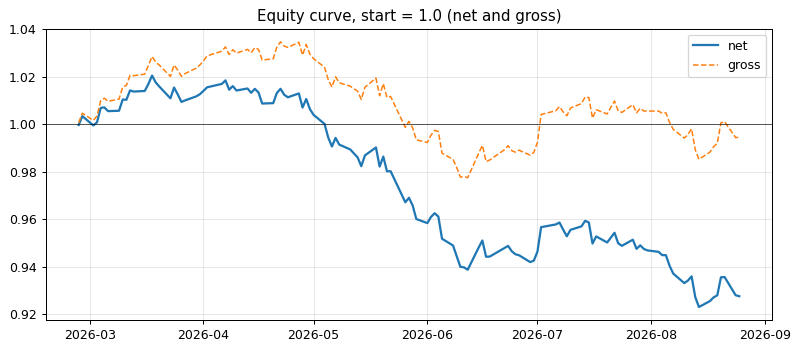

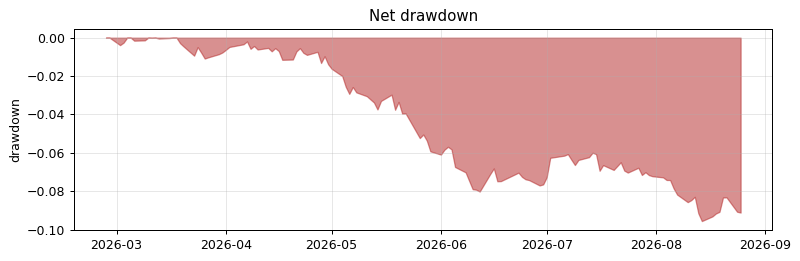

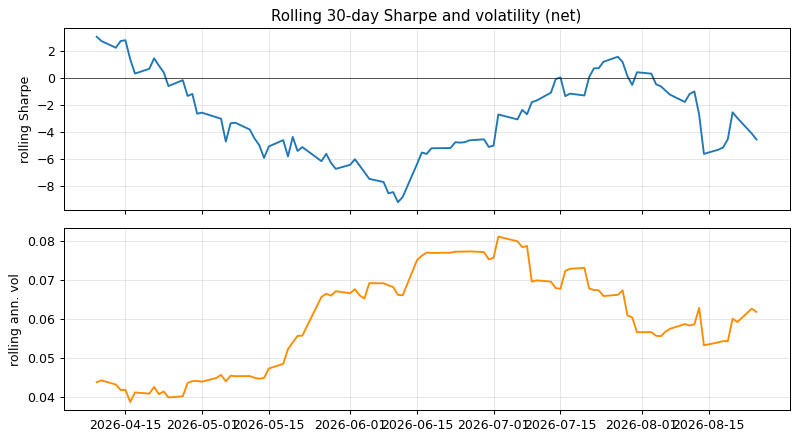

In [13]:
fig = plot_equity(net, gross=gross, title="Equity curve, start = 1.0 (net and gross)")
plt.show()
fig = plot_drawdown(net, title="Net drawdown")
plt.show()
fig = plot_rolling_risk(net, window=30, periods_per_year=ppy, title="Rolling 30-day Sharpe and volatility (net)")
plt.show()

### 8.2 Calendar views and distribution

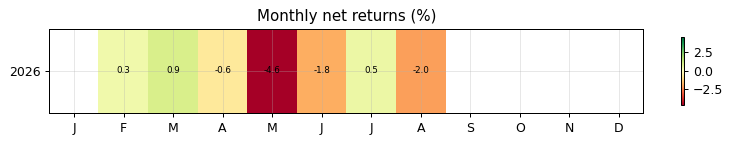

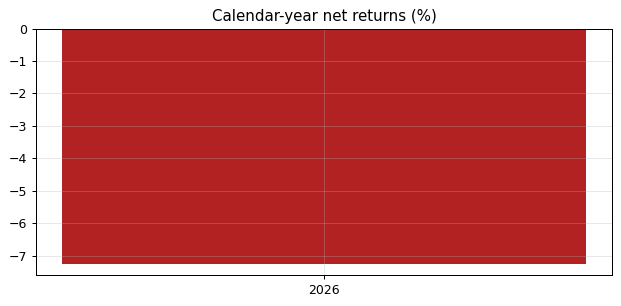

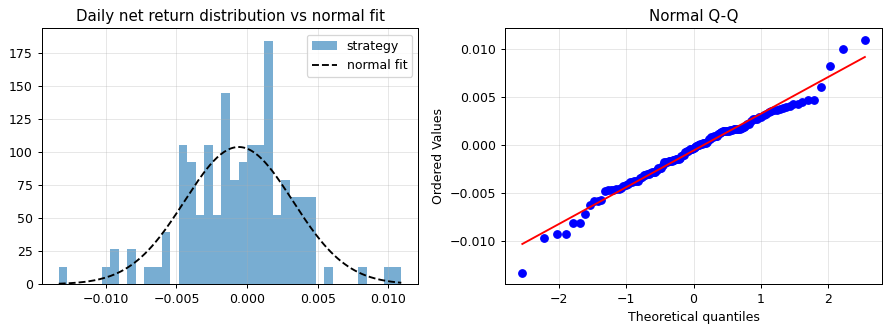

In [14]:
fig = plot_monthly_heatmap(net, title="Monthly net returns (%)")
plt.show()
fig = plot_yearly_bars(net, title="Calendar-year net returns (%)")
plt.show()
fig = plot_return_distribution(net, title="Daily net return distribution vs normal fit")
plt.show()

### 8.3 Exposure, turnover and cost decomposition

Costs are split into **commission** (the fixed or per-share part) and **spread / slippage** (the part that scales with notional). Weekly buckets are used because the sample is about six months.

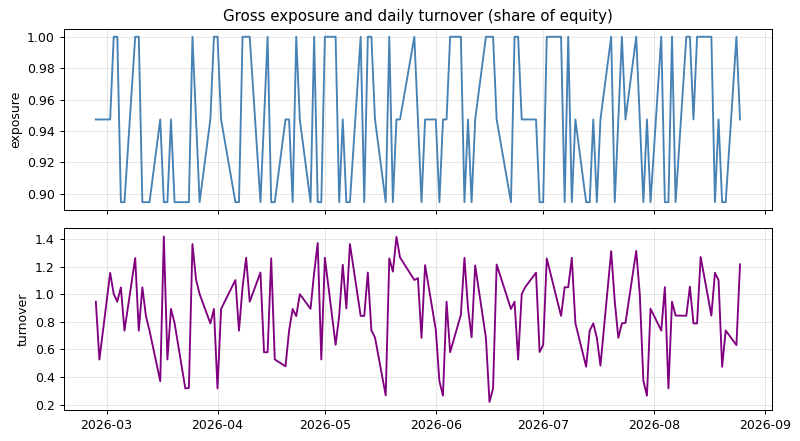

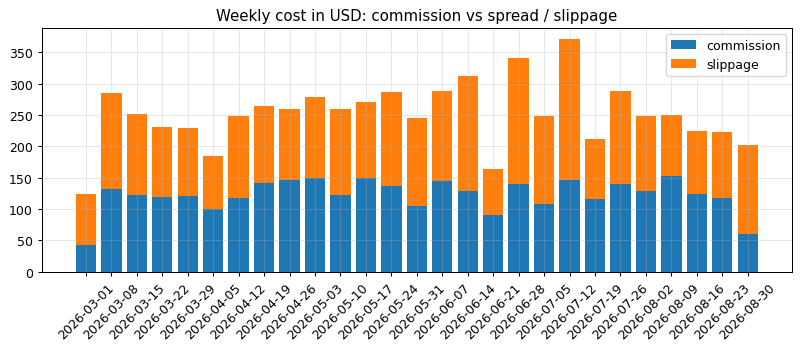

,gross_pnl_usd,cost_usd,net_usd,orders,avg_cost_per_order_usd
fx,-1194.14,1665.74,-2859.88,750,2.22
xau,-275.92,9.99,-285.91,125,0.08
crypto,-3223.69,2897.66,-6121.35,184,15.75
equity,4245.05,2223.63,2021.42,1250,1.78


In [15]:
fig = plot_exposure_turnover(exposure, turnover, title="Gross exposure and daily turnover (share of equity)")
plt.show()

weekly = curve[["commission", "slippage"]].resample("W").sum()
weekly.index = weekly.index.strftime("%Y-%m-%d")
fig = plot_cost_decomposition(weekly, title="Weekly cost in USD: commission vs spread / slippage")
plt.show()

cost_by_class = {}
for klass in ["fx", "xau", "crypto", "equity"]:
    assets = [s for s in UNIVERSE if ASSET_CLASS[s] == klass]
    cost_by_class[klass] = float(result["per_asset"][[f"cost_{s}" for s in assets]].sum().sum())
pnl_by_class = {k: float(result["per_asset"][[f"pnl_{s}" for s in UNIVERSE if ASSET_CLASS[s] == k]].sum().sum())
                for k in ["fx", "xau", "crypto", "equity"]}
by_class = pd.DataFrame({"gross_pnl_usd": pnl_by_class, "cost_usd": cost_by_class})
by_class["net_usd"] = by_class["gross_pnl_usd"] - by_class["cost_usd"]
by_class["orders"] = {k: int((result["per_asset"][[f"cost_{s}" for s in UNIVERSE if ASSET_CLASS[s] == k]] > 0).sum().sum())
                      for k in by_class.index}
by_class["avg_cost_per_order_usd"] = by_class["cost_usd"] / by_class["orders"].replace(0, np.nan)
display(by_class.round(2))
RESULTS["by_class"] = by_class.round(4).to_dict("index")

### 8.4 Contribution per asset and per asset class

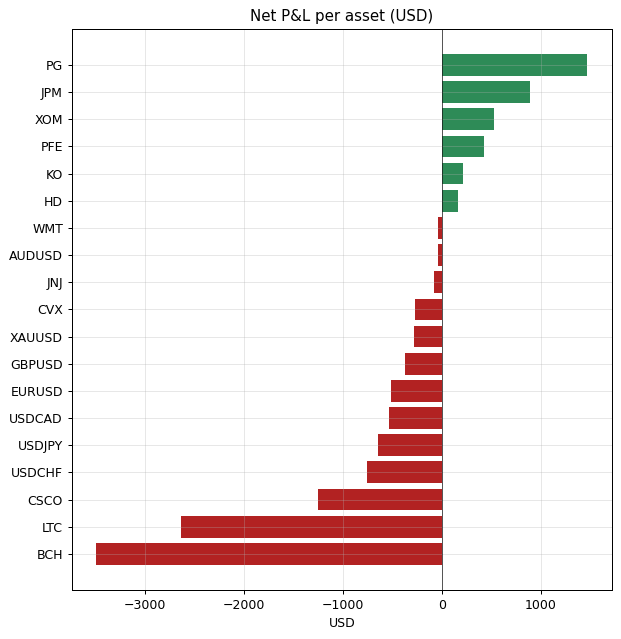

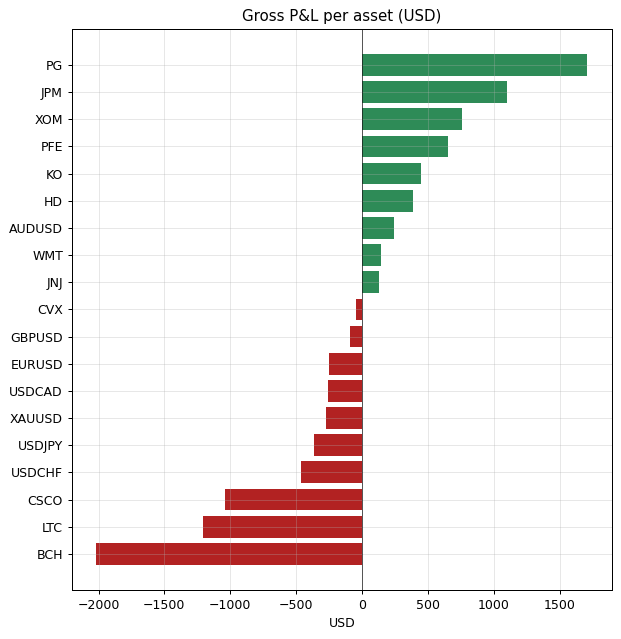

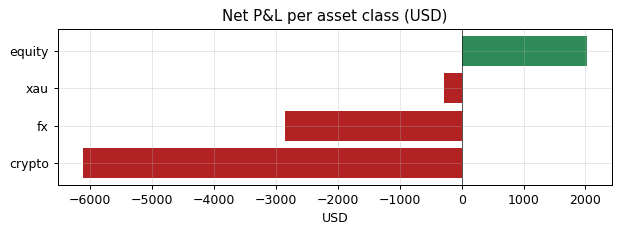

In [16]:
asset_pnl = pd.Series({s: result["per_asset"][f"pnl_{s}"].sum() for s in UNIVERSE})
asset_cost = pd.Series({s: result["per_asset"][f"cost_{s}"].sum() for s in UNIVERSE})
fig = plot_bar_contribution(asset_pnl - asset_cost, title="Net P&L per asset (USD)", xlabel="USD")
plt.show()
fig = plot_bar_contribution(asset_pnl, title="Gross P&L per asset (USD)", xlabel="USD")
plt.show()
fig = plot_bar_contribution(by_class["net_usd"], title="Net P&L per asset class (USD)", xlabel="USD")
plt.show()

### 8.5 Contribution per volatility regime

A regime is defined causally: on each day, the trailing 20-day volatility of the equal-weight basket is compared with the **median of all previous days in the sample**; "high" means above. This uses only information known at the time.

,days,gross_pnl,cost,net
regime,,,,
high_vol,10,457.53,694.71,-237.18
low_vol,115,-906.23,6102.32,-7008.54


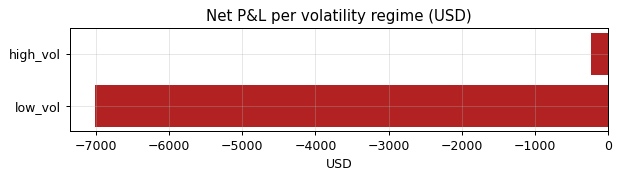

In [17]:
full_basket = data["returns"].mean(axis=1)
tv = full_basket.rolling(20).std().shift(1)
expanding_median = tv.expanding(min_periods=60).median().shift(1)
regime = pd.Series(np.where(tv > expanding_median, "high_vol", "low_vol"), index=tv.index).reindex(curve.index)
regime = regime.where(tv.reindex(curve.index).notna() & expanding_median.reindex(curve.index).notna(), "unclassified")
reg = pd.DataFrame({"gross_pnl": curve["pnl"], "cost": curve["cost"], "regime": regime})
reg_tab = reg.groupby("regime").agg(days=("gross_pnl", "size"), gross_pnl=("gross_pnl", "sum"), cost=("cost", "sum"))
reg_tab["net"] = reg_tab["gross_pnl"] - reg_tab["cost"]
display(reg_tab.round(2))
fig = plot_bar_contribution(reg_tab["net"], title="Net P&L per volatility regime (USD)", xlabel="USD")
plt.show()

### 8.6 Model behaviour: selected order and window tier over time

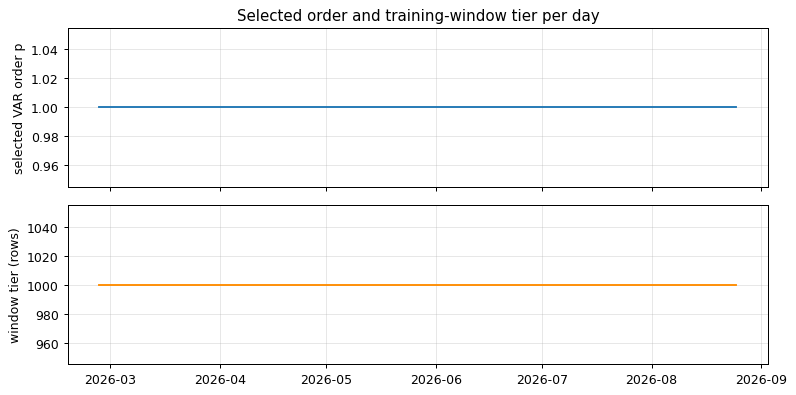

share of days by selected order: {1: 1.0}


In [18]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
axes[0].step(curve.index, curve["p"], where="post")
axes[0].set_ylabel("selected VAR order p")
axes[0].set_title("Selected order and training-window tier per day")
axes[1].step(curve.index, curve["window_tier"], where="post", color="darkorange")
axes[1].set_ylabel("window tier (rows)")
plt.tight_layout()
plt.show()
print("share of days by selected order:", curve["p"].value_counts(normalize=True).sort_index().round(3).to_dict())

### 8.7 Forecast skill against a naive baseline

The model is a forecasting machine, so judge it as one before judging the P&L. Three views, all computed from the logged forecast and realised log-return vectors:

* **Directional hit rate:** how often `sign(forecast) == sign(realised)`, pooled and per asset, with a 95% binomial interval around 50%.
* **Out-of-sample R-squared** `1 - SSE(model) / SSE(naive)`, against (a) a zero forecast and (b) the trailing 250-day mean. A positive value would mean the model beats the naive guess; zero or negative means it does not.
* **Cross-sectional rank IC:** each day, the Spearman correlation between the forecast vector and the realised vector across the 19 assets; the table reports its mean and t-statistic.

,value
directional_hit_rate,0.5124
hit_rate_ci_low,0.4921
hit_rate_ci_high,0.5327
oos_r2_vs_zero,-0.0491
oos_r2_vs_trailing_mean,-0.0430
rank_ic_mean,0.0243
rank_ic_t_stat,0.8789
n_forecasts,2375.0000


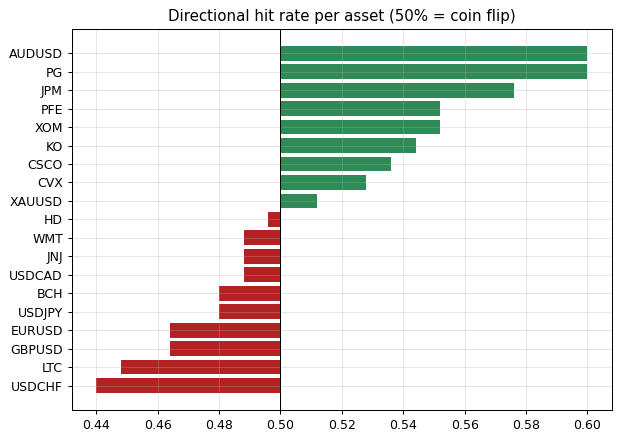

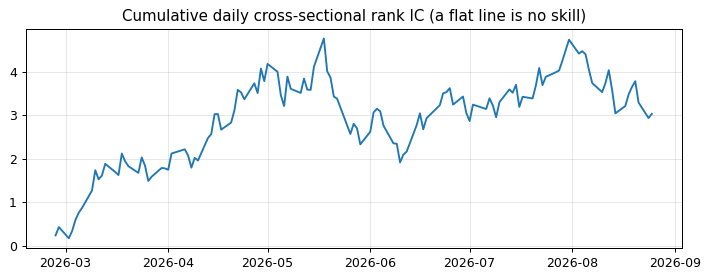

In [19]:
F, R = result["forecasts"], result["realised"]
valid = F.notna() & R.notna()
hit = ((np.sign(F) == np.sign(R)) & (R != 0))[valid]
n_obs = int(valid.sum().sum())
hit_rate = float(hit.sum().sum() / n_obs)
ci = stats.binomtest(int(hit.sum().sum()), n_obs, 0.5).proportion_ci(confidence_level=0.95)

naive_mean = data["returns"].rolling(250).mean().shift(1).reindex(R.index)[UNIVERSE]
sse_model = float(((R - F) ** 2).sum().sum())
sse_zero = float((R ** 2).sum().sum())
sse_mean = float(((R - naive_mean) ** 2).sum().sum())
r2_zero = 1.0 - sse_model / sse_zero
r2_mean = 1.0 - sse_model / sse_mean

ic = pd.Series({d: stats.spearmanr(F.loc[d], R.loc[d])[0] for d in F.index})
ic_mean, ic_t = float(ic.mean()), float(ic.mean() / (ic.std() / np.sqrt(len(ic))))
skill = pd.Series({"directional_hit_rate": hit_rate, "hit_rate_ci_low": ci.low, "hit_rate_ci_high": ci.high,
                   "oos_r2_vs_zero": r2_zero, "oos_r2_vs_trailing_mean": r2_mean,
                   "rank_ic_mean": ic_mean, "rank_ic_t_stat": ic_t, "n_forecasts": n_obs})
display(skill.to_frame("value").round(4))
RESULTS["skill"] = {k: float(v) for k, v in skill.items()}

per_asset_hit = (hit.sum() / valid.sum()).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(per_asset_hit.index, per_asset_hit.values - 0.5, left=0.5,
        color=np.where(per_asset_hit.values >= 0.5, "seagreen", "firebrick"))
ax.axvline(0.5, color="k", lw=0.8)
ax.set_title("Directional hit rate per asset (50% = coin flip)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(ic.cumsum())
ax.set_title("Cumulative daily cross-sectional rank IC (a flat line is no skill)")
fig.tight_layout()
plt.show()

## 9. The killing tests

### 9.1 Cost sweep: is there any cost level at which this works?

Net P&L on day `t` is `gross_t - m * cost_t`. Multiplying the cost by `m` and re-adding shows how the result depends on the cost model, and the break-even multiplier is `gross / cost`. If gross P&L is not positive there is **no** non-negative `m` at which the strategy breaks even: free execution would not save it.

,cost_multiplier,net_pnl_usd,net_return
0,0.00,-448.7000,-0.0045
1,0.25,-2147.9566,-0.0215
2,0.50,-3847.2133,-0.0385
3,1.00,-7245.7266,-0.0725
4,1.50,-10644.2399,-0.1064
5,2.00,-14042.7532,-0.1404


break-even cost multiplier = gross / cost = -0.066  (there is no cost level at which it breaks even)


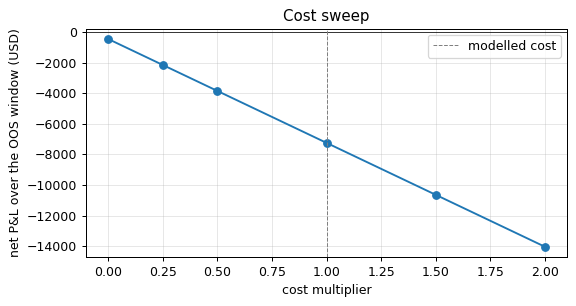

In [20]:
gross_total, cost_total = float(curve["pnl"].sum()), float(curve["cost"].sum())
multipliers = np.array([0.0, 0.25, 0.5, 1.0, 1.5, 2.0])
sweep = pd.DataFrame({"cost_multiplier": multipliers,
                      "net_pnl_usd": [gross_total - m * cost_total for m in multipliers]})
sweep["net_return"] = sweep["net_pnl_usd"] / PARAMS["capital"]
display(sweep.round(4))
breakeven = gross_total / cost_total if cost_total else float("nan")
print(f"break-even cost multiplier = gross / cost = {breakeven:.3f}  "
      f"({'there is no cost level at which it breaks even' if breakeven <= 0 else 'costs can rise by this factor before net P&L turns negative'})")
RESULTS["breakeven_multiplier"] = float(breakeven)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(sweep["cost_multiplier"], sweep["net_pnl_usd"], marker="o")
ax.axhline(0.0, color="k", lw=0.6)
ax.axvline(1.0, color="grey", ls="--", lw=0.8, label="modelled cost")
ax.set_xlabel("cost multiplier")
ax.set_ylabel("net P&L over the OOS window (USD)")
ax.set_title("Cost sweep")
ax.legend()
fig.tight_layout()
plt.show()

### 9.2 Label-permutation test: could a random forecast have done as well?

Gross P&L depends on the forecast only through its sign. Shuffling the **days** of the forecast matrix (keeping each day's cross-section intact, so the position-count and long/short mix are preserved) and re-sizing with the same rule gives the gross P&L distribution of a signal with the same shape but **no relationship to the realised return**. If the actual gross P&L sits inside that distribution, the forecast carries no detectable information. This is gross only: costs are ignored on purpose, to isolate the forecast.

actual gross P&L (no costs) = -449 USD | permutation mean = -588 | 5th-95th pct = [-7,125, 6,202] | share of shuffles at least as good = 0.475


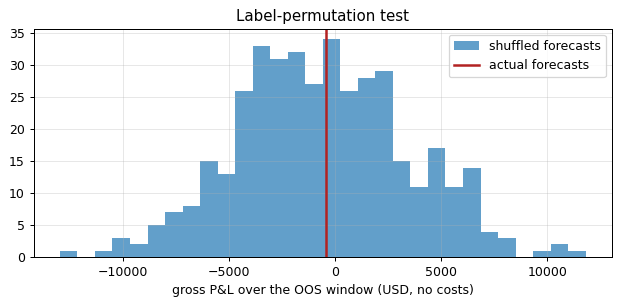

In [21]:
rng = np.random.default_rng(int(PARAMS["random_seed"]))
R_arith = np.expm1(R) if PARAMS["return_method"] == "log" else R


day_scale = (curve["prev_equity"] / PARAMS["capital"]).to_numpy()   # book compounds: same scale as the loop


def gross_pnl_for(forecast_frame: pd.DataFrame) -> float:
    total = 0.0
    for k, (d_f, d_r) in enumerate(zip(forecast_frame.index, R_arith.index)):
        tgt = target_notionals(forecast_frame.loc[d_f].to_dict(), PARAMS)
        total += day_scale[k] * sum(tgt[s] * float(R_arith.at[d_r, s]) for s in UNIVERSE)
    return total


actual = gross_pnl_for(F)
assert abs(actual - curve["pnl"].sum()) < 1e-6, "permutation harness must reproduce the loop's gross P&L"
n_perm = 400 if not SYNTHETIC else 100
perm = np.empty(n_perm)
for b in range(n_perm):
    order = rng.permutation(len(F))
    shuffled = F.iloc[order].copy()
    shuffled.index = F.index
    perm[b] = gross_pnl_for(shuffled)
p_value = float((perm >= actual).mean())
print(f"actual gross P&L (no costs) = {actual:,.0f} USD | permutation mean = {perm.mean():,.0f} | "
      f"5th-95th pct = [{np.percentile(perm, 5):,.0f}, {np.percentile(perm, 95):,.0f}] | "
      f"share of shuffles at least as good = {p_value:.3f}")
RESULTS["perm"] = {"actual": actual, "mean": float(perm.mean()), "p_value": p_value, "n": n_perm}

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(perm, bins=30, alpha=0.7, label="shuffled forecasts")
ax.axvline(actual, color="firebrick", lw=2, label="actual forecasts")
ax.set_xlabel("gross P&L over the OOS window (USD, no costs)")
ax.set_title("Label-permutation test")
ax.legend()
fig.tight_layout()
plt.show()

### 9.3 Cost per order against one slot

Cost per order as a share of one slot's notional, by asset class, at the headline equity. A flat per-order fee is a large share of a small ticket; at the headline equity the per-order fixed minimums are small and what remains is the proportional part (spread, slippage, bps commission), which no amount of capital dilutes. Section 9.4 shows both regimes.

In [22]:
slot = PARAMS["capital"] / len(UNIVERSE)
orders_by_class = by_class["orders"]
frame = pd.DataFrame({"orders": orders_by_class, "avg_cost_per_order_usd": by_class["avg_cost_per_order_usd"]})
frame["cost_bps_of_one_slot"] = frame["avg_cost_per_order_usd"] / slot * 1e4
display(frame.round(2))
print(f"one slot = {slot:,.0f} USD at the headline equity; average daily turnover = {turnover.mean():.1%} of equity; "
      f"orders per day = {(result['per_asset'][[c for c in result['per_asset'].columns if c.startswith('cost_')]] > 0).sum(axis=1).mean():.1f}")

,orders,avg_cost_per_order_usd,cost_bps_of_one_slot
fx,750,2.22,4.22
xau,125,0.08,0.15
crypto,184,15.75,29.92
equity,1250,1.78,3.38


one slot = 5,263 USD at the headline equity; average daily turnover = 87.1% of equity; orders per day = 18.5


### 9.4 Capital sweep: how much of the cost is fixed, how much is proportional?

The headline equity of 100,000 USD is an illustrative assumption, so the whole pipeline is re-run at six equity levels. **Only the initial equity changes**: universe, model, window tiers, cost formulas, sizing rule and the 126-day out-of-sample window are identical, and nothing is retuned.

**What scales with capital:** the target notional per slot (`capital / 19`, compounding with equity), the proportional costs (spread, slippage, bps commission, per-share commission) and therefore P&L in dollars. **What does not scale:** the per-order minimum tickets (flat FX commission, crypto minimum, equity minimum), which are fixed in dollars per order, so they are a shrinking share of a growing book. The fixed share below is computed order by order: an order's cost counts as fixed when a per-order minimum or flat fee is the binding term.

Gross P&L as a share of capital is *not* exactly constant across the sweep: the book compounds on equity, so heavy cost losses at small capital shrink later positions (a path effect, not an edge effect).

capital sweep: 6 full walk-forwards in 32s


capital,5000,10000,25000,50000,100000,250000
gross_usd,6.241,-18.486,-91.631,-210.713,-448.700,-1161.282
cost_usd,2397.270,2575.220,3172.135,4377.289,6797.027,14158.729
net_usd,-2391.029,-2593.706,-3263.766,-4588.002,-7245.727,-15320.011
gross_return,0.120,-0.180,-0.370,-0.420,-0.450,-0.460
net_return,-47.820,-25.940,-13.060,-9.180,-7.250,-6.130
cost_share,47.950,25.750,12.690,8.750,6.800,5.660
cost_bps_of_traded,56.531,26.718,12.293,8.314,6.392,5.296
fixed_cost_usd,2259.500,2259.500,2029.900,2014.850,1983.700,1879.050
proportional_cost_usd,137.770,315.720,1142.235,2362.439,4813.327,12279.679
fixed_share_of_cost,94.250,87.740,63.990,46.030,29.180,13.270


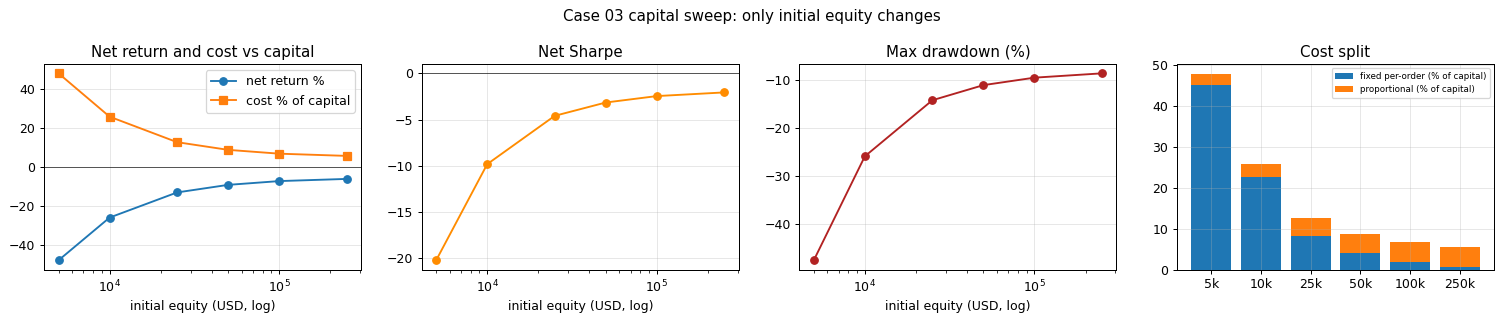

In [23]:
def run_at_capital(cap: float) -> Dict[str, float]:
    p = dict(PARAMS, capital=float(cap))
    r = run_walk_forward(data, p, progress_every=0)
    c = r["equity_curve"]
    cost = float(c["cost"].sum())
    gross_usd = float(c["pnl"].sum())
    fixed = float(c["fixed_cost"].sum())
    ret = c["ret"]
    eq = c["equity"]
    sm = performance_summary(ret, periods_per_year=ppy)
    return {"gross_usd": gross_usd, "cost_usd": cost, "net_usd": float(eq.iloc[-1] - cap),
            "gross_return": gross_usd / cap, "net_return": float(eq.iloc[-1] / cap - 1.0), "cost_share": cost / cap,
            "cost_bps_of_traded": cost / float(c["traded_notional"].sum()) * 1e4,
            "fixed_cost_usd": fixed, "proportional_cost_usd": cost - fixed, "fixed_share_of_cost": fixed / cost,
            "breakeven_multiple": gross_usd / cost, "cagr": float(sm["cagr"]), "sharpe": float(sm["sharpe"]),
            "max_drawdown": float(sm["max_drawdown"]), "position_changes": int(len(r["trade_log"])),
            "orders": int(((r["per_asset"][[x for x in r["per_asset"].columns if x.startswith("cost_")]]) > 0).sum().sum())}


_caps = [5_000, 100_000] if SYNTHETIC else [5_000, 10_000, 25_000, 50_000, 100_000, 250_000]
_t0 = time.time()
cap_sweep = capital_sweep(run_at_capital, _caps)
print(f"capital sweep: {len(_caps)} full walk-forwards in {time.time() - _t0:.0f}s")
show = cap_sweep.copy()
for col in ["gross_return", "net_return", "cost_share", "fixed_share_of_cost", "cagr", "max_drawdown"]:
    show[col] = (show[col] * 100).round(2)
display(show.round(3).set_index("capital").T)
RESULTS["capital_sweep"] = cap_sweep.round(6).to_dict("records")
plot_capital_sweep(cap_sweep, title="Case 02 capital sweep capital sweep: only initial equity changes")
plt.show()

## 10. Interpretation

**No forecasting skill is the lead finding.** The directional hit rate is 51.2% with a 95% interval of [49.2%, 53.3%] that contains 50%; the out-of-sample R-squared is -0.049 against a zero forecast and -0.043 against a trailing mean (the model's error is larger than a naive guess's); the mean rank IC is 0.024 with t = 0.88. Gross P&L is -449 USD (-0.45% of equity) and the label-permutation test places it inside the shuffled distribution (share of shuffles at least as good: 0.47). Equities have a positive gross P&L (4,245 USD) that does not carry crypto (-3,224 USD) or FX (-1,194 USD), and with 125 days that split cannot be told from luck.

**Costs are the second finding, and they are mostly proportional at this equity.** Costs are 6,797 USD (6.8% of equity) on about 18 orders a day and a daily turnover of about 87% of equity, so the net is -7,246 USD with an annualised Sharpe of -2.5 (iid 95% interval [-5.3, 0.3], block 90% interval [-4.8, -0.3]). The break-even cost multiple is negative (-0.066): free execution would not rescue a forecast with no gross edge.

**The capital sweep separates the two parts of cost.** At 5,000 USD the fixed per-order minimums are 94% of cost and total cost is 48% of equity: a small account is destroyed by tickets. At 100,000 USD the fixed share falls to 29% and at 250,000 USD to 13%, but total cost does not vanish: it settles near 5.3 basis points of traded notional, and with turnover of about 107 times equity over the window that is still 5.7% of equity. Net is negative at every capital level tested. The reading changes with capital (from "ticket size" to "turnover times spread"), the verdict does not.

**Model order and convergence.** The selected order is p = 1 on every day, so order selection is not a source of instability here. The VARMAX probe shows the moving-average variant converging for 4 to 10 series with fit time growing roughly 2 to 2.5 times for every two extra series, and the 19-series fit did not finish within its 60 second cap; the case therefore uses a plain VAR. Six months cannot establish the sign of a small true edge; the evidence here is about forecast skill and cost.

## 11. The lesson

**A forecast has to clear the cost of acting on it before it is a strategy, and that cost has to be measured at the ticket size you will actually trade.** Daily refitting of a high-dimensional linear model turns every small change in the fitted coefficients into an order; with fixed per-order fees and a slot of a few hundred dollars each, execution cost is large relative to any plausible edge. Measure the forecast's skill first (hit rate, out-of-sample R-squared, rank IC), the turnover it implies second, and only then the backtest P&L.

## 12. What I would do differently

* **Test skill before building the execution model.** The directional hit rate and out-of-sample R-squared take minutes and would have shown the absence of skill before any cost code was written.
* **Size from a risk budget, not from slot count.** Equal notional per slot with idle capital has no connection to forecast confidence or volatility; use forecast magnitude scaled by trailing volatility, and trade only when the expected gain exceeds the round-trip cost.
* **Reduce dimensionality and turnover.** Fit a regularised or low-rank model (ridge, shrinkage, reduced-rank VAR), refit weekly rather than daily, and add a no-trade band so that small forecast changes do not trigger orders.
* **Respect synchronicity.** Build all series on a common clock (or lag the slower markets) before estimating cross-asset lead-lag.

## 13. How to improve it (ideas, not claims)

* Penalised estimation (LASSO/elastic-net VAR) or a factor-augmented VAR instead of a full 19-by-19 coefficient matrix per lag.
* Forecast the sign with a classifier and trade only when the predicted probability is far from one half.
* Larger capital or fewer, larger tickets so that minimum fees stop dominating (and re-run the cost sweep at that size).
* A longer out-of-sample record (this one is six months) and several non-overlapping test windows, so that a single window cannot decide the verdict.
* Compare against a trivial benchmark with the same turnover (for example "hold yesterday's sign") to separate model skill from simple persistence.

## 14. FAQ

**Why a VAR and not a neural network?** The point of the case is the evaluation, not the model class. A VAR is the cleanest closed-form multivariate baseline; if it cannot beat its costs, a flexible model has to explain why it would.

**Is the loop free of look-ahead?** The training window ends at the close of day `t`, the forecast is applied to the return of `t+1`, and costs use day `t` prices. Section 9.2 would also expose a leak: a leaking forecast would be far outside the permutation distribution.

**Is six months of out-of-sample data enough?** It is enough to *reject* a claim of large positive edge when the interval is as wide and as negative as the one shown; it is not enough to estimate a small true Sharpe.

**Do the numbers change with a different universe or capital?** They can. The universe and the 100,000 USD starting capital are the values this case tests, and the capital sweep shows how the result moves with equity. Change the universe and re-run the test to see whether the verdict holds.

**Does the failure reproduce in synthetic mode?** No. Synthetic data is a driftless random walk: gross P&L is noise around zero by construction, and costs follow the synthetic spread. The mode exists so that the code can be run end to end by anyone.

## 15. References

* Lutkepohl, H. (2005). *New Introduction to Multiple Time Series Analysis.* Springer.
* Seabold, S. and Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference.*
* Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control.*
* Bailey, D. H. and Lopez de Prado, M. (2014). The deflated Sharpe ratio. *Journal of Portfolio Management.*
* Efron, B. and Tibshirani, R. (1993). *An Introduction to the Bootstrap.* Chapman and Hall.

## 16. Disclaimer

This notebook is educational. It documents a failed research experiment and is not financial advice or a recommendation to trade any instrument. Past or hypothetical results do not predict future results. The author makes no warranty about the accuracy of any figure, and the code is provided as is.

In [24]:
if os.environ.get("AUTOPSY_RESULTS_JSON"):
    Path(os.environ["AUTOPSY_RESULTS_JSON"]).write_text(json.dumps(RESULTS, indent=2, default=str))
print("done")

done
